# Day 4-02｜シュートする選手を選び、骨格と関節角度を求める

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day4/d4_02_yolo_pose_and_shot_lab_ja.ipynb)

[English](d4_02_yolo_pose_and_shot_lab_en.ipynb) | [Japanese](d4_02_yolo_pose_and_shot_lab_ja.ipynb) | [Traditional Chinese](d4_02_yolo_pose_and_shot_lab.ipynb)

> Python によるバスケットボール映像分析  
> シュート候補モデルと YOLO pose を組み合わせ、各フレームでシュートする選手、
> 人体のキーポイント、肘・肩・膝の角度を求める。

## 学習目標
- `shot_detection.pt` で各フレームの `shot_score` と選手の候補矩形を得る。
- `yolov8n-pose.pt` でキーポイントを求め、複数人の映像でも同じ選手を選び続ける。
- 左右の関節から 2 次元の角度を計算し、CSV、曲線図、重畳動画を出力する。
- 骨格が他人に移っていないか確認し、`wrist` が現在の手首位置であって球の軌跡ではないと理解する。

## 完了の目安
- シュート前後の骨格が、おおむね同じ選手に重なっている。
- `shot_score` のピークが、目で見たシュート動作とおおむね一致する。
- 角度曲線に不自然な単発の跳びが多くなく、手首と身体の表示位置が妥当である。

## 出力
- `assets/results/d4_02_pose_angles.csv`
- `assets/results/d4_02_pose_angle_plot.png`
- `assets/results/d4_02_pose_overlay_preview.mp4`


## Setup｜実行環境、モデル、結果フォルダを確認する

### Colab のランタイム設定

実行前に Colab の **ランタイム → ランタイムのタイプを変更** を開き、ハードウェア アクセラレータを
**T4 GPU** にする。別の NVIDIA GPU も利用できる。**TPU は選択しない**。
本教材の Ultralytics／PyTorch は TPU を直接利用せず、CPU での実行になるためである。

Colab では先に `init_colab_ja.ipynb` を実行する。次のセルは Drive のマウント、教材ルートの探索、
モデルの確認を行う。実行後の `results directory` は、次の場所になっている必要がある。
`/content/drive/MyDrive/basketball_hackathon/course/assets/results`。

初期設定では先頭 180 フレームを `POSE_STRIDE = 1` で処理する。簡単な確認では `2` にできるが、リリースの
分析前には `1` に戻す。2 にすると時間分解能が半分になる。


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo, prepare_day4_workspace  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)
DAY4_MODELS, RESULTS = prepare_day4_workspace(COURSE_ROOT)
print("Day 4 models:", {name: str(path) for name, path in DAY4_MODELS.items()})
print("results directory:", RESULTS)


教材ルート： /Users/henry753951/Developer/sandbox/basketball-hackathon-course
素材フォルダ： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
共通モジュール： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src
Day 4 models: {'ball_rim': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/ball_rimV8.pt', 'shot_detection': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/shot_detection.pt', 'yolo_pose': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/pose/yolov8n-pose.pt'}
results directory: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results


## Step 1｜Day 4-01 と同じ動画を読む

このセルは入力を選び、表示、描画、実行デバイスの関数を読み込む。`pick_first_converted_video` は
`assets/converted/` の動画をファイル名順で選ぶ。教材の標準構成では、
`student_video.mp4` が `video_001.mp4` より先に並ぶため、作成済みなら三つの Notebook ともそれを使う。

`using video` が Day 4-01 と完全に同じか確認する。別動画の CSV ではフレームが一致しない。


In [2]:
from src.plot_utils import plot_angle_series
from src.shooting_utils import render_pose_overlay_video
from src.video_utils import display_video_in_notebook, list_videos, pick_first_converted_video
from src.yolo_utils import preferred_inference_device

converted_videos = list_videos(COURSE_ROOT / "assets" / "converted")
video_path = pick_first_converted_video(COURSE_ROOT)

print("converted videos:", [path.name for path in converted_videos])
print("using video:", video_path)


converted videos: ['video_001.mp4']
using video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/converted/video_001.mp4


## Step 2｜シュート候補と人体姿勢を同時に推論する

この単元の主要なモデル処理である。

1. `shot_detection.pt` で各フレームの `shot_score` と人物候補矩形を得る。
2. `yolov8n-pose.pt` で各人物の 17 個の COCO キーポイントを求める。
3. 明確なシュート矩形があれば最も合う人物を選ぶ。信号が弱まった場合は、前の人物位置を使って維持する。
4. 左右の肩、肘、手首、股関節、膝、足首から 2 次元角度を求める。

`POSE_SIDE = "right"` が選ぶのは、簡略列 `elbow_angle`、`shoulder_angle`、`knee_angle` に表示する側だけである。
CSV には左右とも残る。実行後は `rows`、`shot_score`、人物矩形、キーポイントの各項目を確認する。


In [3]:
from src.shot_event_utils import extract_yolo_shot_pose_sequence

POSE_SIDE = "right"
POSE_STRIDE = 1
POSE_MAX_FRAMES = 180
DEVICE = preferred_inference_device()
pose_model_path = DAY4_MODELS["yolo_pose"]
shot_model_path = DAY4_MODELS["shot_detection"]

# 各行に 1 フレームのスコア、選手矩形、関節点、左右角度を保存します。
pose_df = extract_yolo_shot_pose_sequence(
    video_path,
    pose_model_path=pose_model_path,
    shot_model_path=shot_model_path,
    stride=POSE_STRIDE,
    side=POSE_SIDE,
    max_frames=POSE_MAX_FRAMES,
    device=DEVICE,
)

print("pose model:", pose_model_path)
print("shot model:", shot_model_path)
print("inference device:", DEVICE)
print("rows:", len(pose_df))
pose_df.head()


pose model: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/pose/yolov8n-pose.pt
shot model: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/shot_detection.pt
inference device: mps
rows: 180


,frame,pose_confidence,person_x1,person_y1,person_x2,person_y2,shot_score,shot_x1,shot_y1,shot_x2,...,wrist_y,hip_x,hip_y,knee_x,knee_y,ankle_x,ankle_y,elbow_angle,shoulder_angle,knee_angle
0,0,0.881945,484.120300,301.191711,564.567688,459.987122,0.048898,274.417480,73.610489,321.188721,...,348.821472,501.978760,377.921387,504.295929,412.917236,497.037109,446.414001,130.329608,51.770945,163.984760
1,1,0.879264,483.665283,301.186890,562.171265,459.951599,0.057007,483.109680,321.378357,566.225891,...,343.761932,501.564453,378.086914,503.613403,413.526093,498.366913,446.844971,125.659493,59.674381,167.742583
2,2,0.875369,483.463013,301.123627,562.657715,459.636383,0.067450,482.471466,321.599243,566.293701,...,346.450897,500.870636,377.804779,502.778259,411.950317,498.670715,445.360291,131.354881,58.430338,169.793377
3,3,0.872239,483.215149,301.146667,562.452087,459.642029,0.201517,742.554321,330.310242,790.668823,...,346.645752,500.361755,377.540039,502.496735,411.829407,498.758942,445.427490,133.941179,60.313446,170.089095
4,4,0.873565,482.576935,301.136566,560.612549,459.712250,0.159528,742.443359,329.232910,789.317993,...,346.593231,499.765015,377.353607,502.490997,411.795349,498.468658,445.480652,137.336443,60.971538,168.665200


## Step 3｜フレームごとのデータを保存し、角度曲線を描く

CSV は Day 4-03 の入力、曲線図は簡易確認に使う。`to_csv` で各フレームのシュートスコア、
人物矩形、キーポイント、角度を保存し、`plot_angle_series` で肘、膝、肩の時系列を描く。

構えの沈み込み、ボールを上げる動作、投げた後の伸展が連続して変化するかを見る。1 フレームだけ急変したら、
先に関節点を確認する。遮蔽、横向き、ぼけが 2 次元姿勢に影響するため、数値の異常が動作の異常とは限らない。


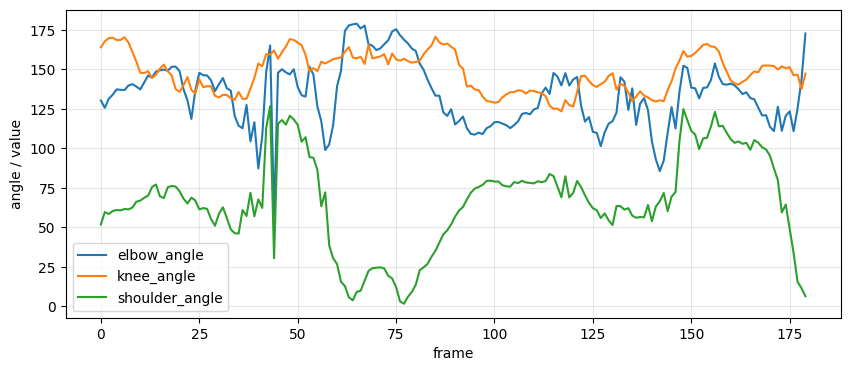

saved: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_02_pose_angles.csv
saved: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_02_pose_angle_plot.png


In [4]:
pose_csv = RESULTS / "d4_02_pose_angles.csv"
angle_plot_png = RESULTS / "d4_02_pose_angle_plot.png"

# CSV を Day 4-03 の入力にし、図で時間変化を確認します。
pose_df.to_csv(pose_csv, index=False)
plot_angle_series(
    pose_df,
    ["elbow_angle", "knee_angle", "shoulder_angle"],
    output_path=angle_plot_png,
)

print("saved:", pose_csv)
print("saved:", angle_plot_png)


## Step 4｜骨格を動画に重ねて確認する

`pose_df` の骨格を元動画に描く。白い骨格は同じ選手に重なる必要がある。ピンク色の `wrist` は
その時点の手首位置だけで、手首の履歴線でも球の軌跡でもない。

別の人物を選んでいれば、後でリリース時刻や角度が出ても分析には使えない。該当フレームを記録し、
Day 4-03 の解釈を進める前に確認する。


In [5]:
pose_overlay_mp4 = RESULTS / "d4_02_pose_overlay_preview.mp4"

# highlight_joint は現在の手首だけを描き、人物は pose_df で決まります。
render_pose_overlay_video(
    video_path,
    pose_df,
    pose_overlay_mp4,
    max_frames=180,
    highlight_joint="wrist",
)

print("saved:", pose_overlay_mp4)
display_video_in_notebook(pose_overlay_mp4, width=720, muted=True, loop=True)


$ /opt/homebrew/bin/ffmpeg -y -i /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_02_pose_overlay_preview.mp4 -an -vcodec libx264 -pix_fmt yuv420p -movflags +faststart -preset veryfast -crf 23 /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_02_pose_overlay_preview.notebook.mp4


saved: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_02_pose_overlay_preview.mp4


## Checks｜Day 4-03 に進む前に

- シュート前後の骨格が同じ選手に重なり、別の人物に移っていない。
- `wrist` が現在の手首上にあり、球と混同していない。
- `shot_score` のピークがシュート動作とおおむね合い、角度に不自然な跳びが多くない。
- `d4_02_pose_angles.csv` が `assets/results/` にあり、元動画が Day 4-01 と同じである。

次の Day 4-03 では、シュート候補、選手の手首、全ボール候補を組み合わせ、イベントごとの球の軌跡を作る。
